# Landslide susceptibility, Pasang Lhamu Highway corridor, Nepal (prototype)


**Data**
- Landslide points: NASA *High Mountain Asia Multitemporal Landslide Inventories* (Amatya & Kirschbaum), Pasang Lhamu Highway, 2009 to 2018
- Elevation: Copernicus DEM GLO-30 (30 m)
- Rainfall: CHIRPS v2.0 (0.05 degree)
- Rivers and roads: OpenStreetMap

**Method:** terrain features (elevation, slope, curvature) from the DEM, random forest, spatial cross-validation. Rainfall, river distance and road distance were tested as extra features.

**Status:** preliminary prototype. The landslide points end in 2018.



## 1. Setup

In [1]:
!pip install -q geopandas rasterio shapely pyproj

import os, glob, zipfile
import numpy as np, pandas as pd, geopandas as gpd, rasterio, shapely
import matplotlib.pyplot as plt
from rasterio.merge import merge
from rasterio.transform import rowcol, xy
from pyproj import Transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/landslide_project')
UTM = "EPSG:32645"   # metric coordinate system for distances in metres

Mounted at /content/drive


## 2. Landslide points

The NASA inventory has landslide initiation points per year. Steps: remove near-duplicates (same year, about 100 m), and leave out the 2015 points, which are mostly triggered by the Gorkha earthquake rather than by ordinary conditions.

In [2]:

for z in glob.glob("nasa_points/**/*.zip", recursive=True):
    zipfile.ZipFile(z).extractall(os.path.dirname(z))

BASE = "nasa_points/HMA_MTLI_v01_landslide_inventory/"
pts = gpd.read_file(BASE + "HMA_MTLI_v01_Pasang_Lhamu_Highway.shp")
pts["lon"], pts["lat"] = pts.geometry.x, pts.geometry.y
pts["key"] = (pts["lon"].round(3).astype(str) + "_" + pts["lat"].round(3).astype(str)
              + "_" + pts["Year"].astype(str))
pts = pts.drop_duplicates("key").drop(columns="key")

all_pts = pts.copy()              # every known landslide (used to keep 'no landslide' points away from them)
pl = pts[pts["Year"] != 2015].copy()   # landslide points used for training

print("Points after removing duplicates:", len(all_pts))
print("Points used (without 2015):", len(pl))
print(pl["Year"].value_counts().sort_index())

# the satellite image footprint for this highway: we only sample inside it
fp = gpd.read_file(BASE + "HMA_MTLI_v01_Footprint.shp")
pl_fp = fp[fp["Highway"].astype(str).str.contains("Pasang", case=False)]
print("Footprints for Pasang Lhamu:", len(pl_fp))

Points after removing duplicates: 1514
Points used (without 2015): 529
Year
2009    175
2010     69
2012     83
2013     29
2014     23
2016     45
2017     73
2018     32
Name: count, dtype: int64
Footprints for Pasang Lhamu: 5


## 3. Terrain from the DEM

Slope, aspect (the direction a slope faces), curvature, and a simple sunlight index for a winter morning (used later to check for image bias).

In [3]:
files = ["Copernicus_DSM_COG_10_N27_00_E085_00_DEM.tif",
         "Copernicus_DSM_COG_10_N28_00_E085_00_DEM.tif"]
srcs = [rasterio.open(f) for f in files]
mosaic, transform = merge(srcs)
nodata = srcs[0].nodata
for s in srcs:
    s.close()
dem = mosaic[0].astype("float32")
if nodata is not None:
    dem[dem == nodata] = np.nan

# pixel size: about 30.9 m north-south, and 30.9 * cos(latitude) east-west
dy = 30.9
dx = 30.9 * np.cos(np.radians(28.0))
dz_dy, dz_dx = np.gradient(dem, dy, dx)
slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
aspect = np.degrees(np.arctan2(-dz_dx, dz_dy)) % 360
aspect_sin, aspect_cos = np.sin(np.radians(aspect)), np.cos(np.radians(aspect))
curv = np.gradient(dz_dx, axis=1) / dx + np.gradient(dz_dy, axis=0) / dy

# sunlight index (1 = facing the sun, 0 or below = in self-shadow), winter sun about 10:30 am at 28 N
az, el = 160, 35
zen = np.radians(90 - el)
s_rad, a_rad = np.radians(slope), np.radians(aspect)
hs = np.cos(zen) * np.cos(s_rad) + np.sin(zen) * np.sin(s_rad) * np.cos(np.radians(az) - a_rad)

print("DEM size:", dem.shape)

DEM size: (7200, 3600)


## 4. 'No landslide' points

A model needs examples of places without mapped landslides. We draw random points that are

- inside the image footprint and within 3 km of a mapped landslide,
- at least 300 m from any known landslide,
- inside the elevation range of the landslide points.

Later we add a lighting condition.

In [4]:
fp_u = pl_fp.to_crs(UTM).union_all().intersection(
    all_pts.to_crs(UTM).buffer(3000).union_all())
too_close = all_pts.to_crs(UTM).buffer(300).union_all()

r, c = rowcol(transform, pl["lon"].values, pl["lat"].values)
r, c = np.array(r), np.array(c)
emin, emax = np.nanmin(dem[r, c]), np.nanmax(dem[r, c])
thr = np.percentile(hs[r, c], 2)   # lowest sunlight level seen at landslide points
print("Landslide elevation range (m):", round(emin), "to", round(emax))
print("Sunlight threshold (2nd percentile):", round(thr, 2))

def sample_negatives(n, require_lit=False, seed=42):
    rng = np.random.default_rng(seed)
    minx, miny, maxx, maxy = fp_u.bounds
    kept, got = [], 0
    while got < n:
        xs = rng.uniform(minx, maxx, 5000)
        ys = rng.uniform(miny, maxy, 5000)
        cand = gpd.GeoSeries(gpd.points_from_xy(xs, ys), crs=UTM)
        cand = cand[cand.within(fp_u) & ~cand.within(too_close)].to_crs("EPSG:4326")
        rr, cc = rowcol(transform, cand.x.values, cand.y.values)
        rr, cc = np.array(rr), np.array(cc)
        inside = (rr >= 0) & (rr < dem.shape[0]) & (cc >= 0) & (cc < dem.shape[1])
        cand, rr, cc = cand[inside], rr[inside], cc[inside]
        good = (dem[rr, cc] >= emin) & (dem[rr, cc] <= emax)
        if require_lit:
            good &= (hs[rr, cc] >= thr)
        kept.append(cand[good])
        got += int(good.sum())
    return pd.concat(kept).iloc[:n]

def build_table(neg):
    a = pd.DataFrame({"lon": pl["lon"].values, "lat": pl["lat"].values,
                      "year": pl["Year"].values, "landslide": 1})
    b = pd.DataFrame({"lon": neg.x.values, "lat": neg.y.values,
                      "year": np.nan, "landslide": 0})
    d = pd.concat([a, b], ignore_index=True)
    rr, cc = rowcol(transform, d["lon"].values, d["lat"].values)
    rr, cc = np.array(rr), np.array(cc)
    d["elevation"] = dem[rr, cc]
    d["slope"] = slope[rr, cc]
    d["aspect"] = aspect[rr, cc]
    d["aspect_sin"] = aspect_sin[rr, cc]
    d["aspect_cos"] = aspect_cos[rr, cc]
    d["curvature"] = curv[rr, cc]
    d["lit"] = hs[rr, cc]
    d = d.dropna(subset=["elevation", "slope"])
    # spatial blocks of 0.1 degrees, so test areas are not next to training areas
    d["block"] = (d["lon"] // 0.1).astype(int).astype(str) + "_" + (d["lat"] // 0.1).astype(int).astype(str)
    return d

Landslide elevation range (m): 622 to 4195
Sunlight threshold (2nd percentile): 0.17


## 5. Spatial cross-validation

Landslides cluster in space, so a random train/test split would be too optimistic. Here the data is split into 0.1 degree blocks and each test fold is a set of blocks the model has not seen. The score is AUC (0.5 = guessing, 1.0 = perfect).

In [5]:
def run(data, features, label):
    X, y, g = data[features], data["landslide"], data["block"]
    aucs = []
    importances = np.zeros(len(features))
    for tr, te in GroupKFold(n_splits=5).split(X, y, g):
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                   random_state=42, n_jobs=-1)
        m.fit(X.iloc[tr], y.iloc[tr])
        aucs.append(roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
        importances += m.feature_importances_ / 5
    print("\n" + label)
    print("AUC per fold:", np.round(aucs, 3), "| mean:", round(np.mean(aucs), 3))
    print(pd.Series(importances, index=features).sort_values(ascending=False).round(3))

## 6. Check for an imaging bias (slope direction)

A first model with random 'no landslide' points relied mostly on slope direction: almost all landslide points face south or southeast. The inventory was mapped from optical satellite images, where slopes in shadow are hard to read, so this pattern may come partly from how the images were taken and not only from real landslide behaviour. The checks below look at that.

In [6]:
naive = build_table(sample_negatives(len(pl), require_lit=False))

labels = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
naive["facing"] = pd.cut((naive["aspect"] + 22.5) % 360, bins=np.arange(0, 361, 45),
                         labels=labels, right=False)
tab = pd.crosstab(naive["facing"], naive["landslide"])
tab["landslide_share"] = (tab[1] / (tab[0] + tab[1])).round(2)
print("Slope direction vs landslide (0 = random point, 1 = landslide):")
print(tab)

print("\nShare of points in self-shadow (sunlight index <= 0):")
print((naive["lit"] <= 0).groupby(naive["landslide"]).mean().round(3))

run(naive, ["elevation", "slope", "aspect_sin", "aspect_cos", "curvature"], "Random negatives, with aspect")
run(naive, ["elevation", "slope", "curvature"], "Random negatives, without aspect")

Slope direction vs landslide (0 = random point, 1 = landslide):
landslide   0    1  landslide_share
facing                             
N          71    2             0.03
NE         66    5             0.07
E          55   34             0.38
SE         71  159             0.69
S          67  169             0.72
SW         57  111             0.66
W          73   39             0.35
NW         69   10             0.13

Share of points in self-shadow (sunlight index <= 0):
landslide
0    0.074
1    0.006
Name: lit, dtype: float64

Random negatives, with aspect
AUC per fold: [0.822 0.861 0.811 0.881 0.802] | mean: 0.835
aspect_cos    0.408
elevation     0.196
slope         0.176
curvature     0.129
aspect_sin    0.092
dtype: float64

Random negatives, without aspect
AUC per fold: [0.785 0.735 0.72  0.72  0.694] | mean: 0.731
elevation    0.372
slope        0.353
curvature    0.275
dtype: float64


## 7. Lighting-matched 'no landslide' points

To reduce the bias, the 'no landslide' points are now drawn only from pixels that are lit about as well as the landslide points. Then the model is run with and without slope direction.

In [7]:
data = build_table(sample_negatives(len(pl), require_lit=True))
data.to_csv("training_points_lit.csv", index=False)
print(data["landslide"].value_counts())
print(data.groupby("landslide")[["elevation", "slope", "lit"]].mean().round(2))

run(data, ["elevation", "slope", "aspect_sin", "aspect_cos", "curvature"], "Lighting-matched, with aspect")
run(data, ["elevation", "slope", "curvature"], "Lighting-matched, without aspect (final model features)")

landslide
1    529
0    529
Name: count, dtype: int64
             elevation  slope   lit
landslide                          
0          2230.979980  28.85  0.58
1          1847.329956  35.77  0.78

Lighting-matched, with aspect
AUC per fold: [0.774 0.83  0.838 0.838 0.784] | mean: 0.813
aspect_cos    0.308
slope         0.247
elevation     0.205
curvature     0.135
aspect_sin    0.105
dtype: float64

Lighting-matched, without aspect (final model features)
AUC per fold: [0.725 0.769 0.795 0.724 0.711] | mean: 0.745
slope        0.424
elevation    0.329
curvature    0.247
dtype: float64


## 8. Final model and susceptibility map

The final model uses elevation, slope and curvature only (no aspect), because of the possible imaging bias above. It is fitted on all points and applied to a grid (about 180 m spacing) inside the corridor footprint, within the elevation range of the training landslides.

Feature importance:
elevation    0.329
slope        0.426
curvature    0.245
dtype: float64
Grid points mapped: 70331


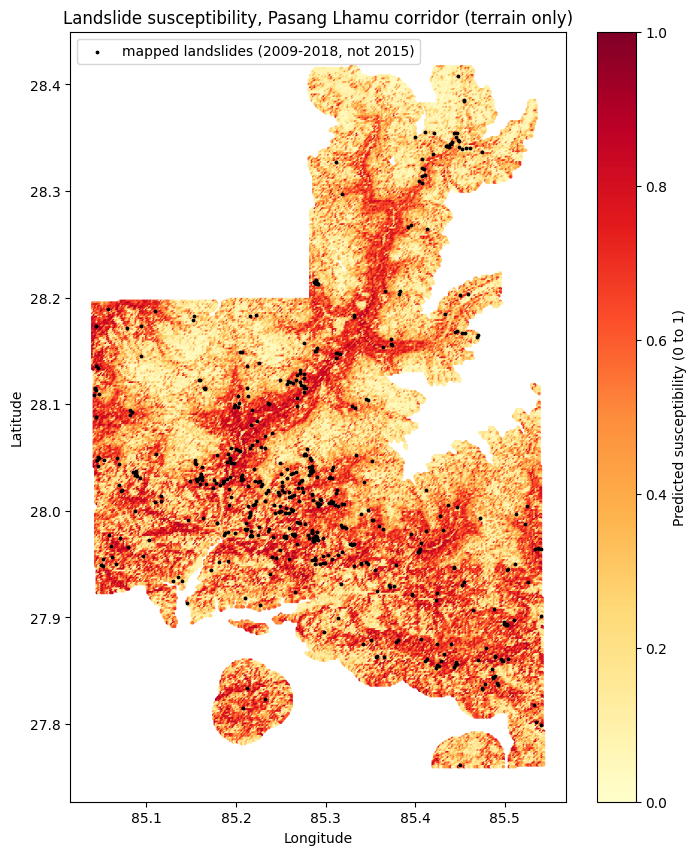

Saved susceptibility_map.png and susceptibility_grid.csv


In [8]:
feats = ["elevation", "slope", "curvature"]
final = RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                               random_state=42, n_jobs=-1)
final.fit(data[feats], data["landslide"])
print("Feature importance:")
print(pd.Series(final.feature_importances_, index=feats).round(3))

rr, cc = np.meshgrid(np.arange(0, dem.shape[0], 6), np.arange(0, dem.shape[1], 6), indexing="ij")
rr, cc = rr.ravel(), cc.ravel()
xs, ys = xy(transform, rr, cc)
lon, lat = np.array(xs), np.array(ys)

bb = pl_fp.total_bounds
sel = (lon >= bb[0]) & (lon <= bb[2]) & (lat >= bb[1]) & (lat <= bb[3])
rr, cc, lon, lat = rr[sel], cc[sel], lon[sel], lat[sel]

X, Y = Transformer.from_crs("EPSG:4326", UTM, always_xy=True).transform(lon, lat)
inside = shapely.contains_xy(fp_u, X, Y)
rr, cc, lon, lat = rr[inside], cc[inside], lon[inside], lat[inside]

grid = pd.DataFrame({"elevation": dem[rr, cc], "slope": slope[rr, cc], "curvature": curv[rr, cc]})
good = grid["elevation"].between(emin, emax) & grid.notna().all(axis=1)
grid, lon, lat = grid[good], lon[good.values], lat[good.values]
grid["risk"] = final.predict_proba(grid[feats])[:, 1]
print("Grid points mapped:", len(grid))

fig, ax = plt.subplots(figsize=(8, 10))
sc = ax.scatter(lon, lat, c=grid["risk"], s=2, cmap="YlOrRd", vmin=0, vmax=1)
ax.scatter(pl["lon"], pl["lat"], s=3, c="black", label="mapped landslides (2009-2018, not 2015)")
plt.colorbar(sc, label="Predicted susceptibility (0 to 1)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(loc="upper left")
ax.set_title("Landslide susceptibility, Pasang Lhamu corridor (terrain only)")
plt.savefig("susceptibility_map.png", dpi=200, bbox_inches="tight")
plt.show()

out = grid.copy()
out["lon"], out["lat"] = lon, lat
out.to_csv("susceptibility_grid.csv", index=False)
print("Saved susceptibility_map.png and susceptibility_grid.csv")

## 9. Rainfall (CHIRPS)

Adds long-term mean rainfall (2009 to 2018, without 2015) as a feature: mean annual rainfall and mean monsoon (June to September) rainfall. CHIRPS has 0.05 degree (about 5 km) pixels, so rainfall varies smoothly compared with the 30 m terrain features.

In [9]:
import io, requests
from scipy.interpolate import RegularGridInterpolator

bb = pl_fp.total_bounds                      # lon_min, lat_min, lon_max, lat_max
pad = 0.15
lat0, lat1 = bb[1] - pad, bb[3] + pad
lon0, lon1 = bb[0] - pad, bb[2] + pad

url = ("https://coastwatch.pfeg.noaa.gov/erddap/griddap/chirps20GlobalMonthlyP05.csv"
       f"?precip[(2009-01-01):1:(2018-12-01)][({lat0:.2f}):1:({lat1:.2f})][({lon0:.2f}):1:({lon1:.2f})]")
resp = requests.get(url, timeout=120)
resp.raise_for_status()
rain = pd.read_csv(io.StringIO(resp.text), skiprows=[1])   # row 2 holds units
rain["time"] = pd.to_datetime(rain["time"])
rain = rain[(rain["time"].dt.year != 2015) & (rain["precip"] >= 0)]
print(rain.shape, rain["precip"].describe().round(1).to_dict())

# mean monthly values -> annual and monsoon means (mm per year / per season)
rain["year"], rain["month"] = rain["time"].dt.year, rain["time"].dt.month
n_years = rain["year"].nunique()
annual = rain.groupby(["latitude", "longitude"])["precip"].sum() / n_years
monsoon = (rain[rain["month"].between(6, 9)]
           .groupby(["latitude", "longitude"])["precip"].sum() / n_years)

def to_interp(series):
    g = series.unstack("longitude").sort_index().sort_index(axis=1)
    return RegularGridInterpolator((g.index.values, g.columns.values), g.values,
                                   bounds_error=False, fill_value=None)

f_annual, f_monsoon = to_interp(annual), to_interp(monsoon)

def add_rain(df, lon_col="lon", lat_col="lat"):
    pts = np.column_stack([df[lat_col].values, df[lon_col].values])
    df = df.copy()
    df["rain_annual"] = f_annual(pts)
    df["rain_monsoon"] = f_monsoon(pts)
    return df

data_r = add_rain(data)
print(data_r.groupby("landslide")[["rain_annual", "rain_monsoon"]].mean().round(0))

(36720, 4) {'count': 36720.0, 'mean': 118.8, 'std': 142.7, 'min': 1.0, '25%': 15.0, '50%': 48.3, '75%': 188.5, 'max': 933.5}
           rain_annual  rain_monsoon
landslide                           
0               1523.0        1213.0
1               1548.0        1246.0


In [10]:
base = ["elevation", "slope", "curvature"]
run(data_r, base, "Terrain only (final model so far)")
run(data_r, base + ["rain_annual", "rain_monsoon"], "Terrain + rainfall")


Terrain only (final model so far)
AUC per fold: [0.725 0.769 0.795 0.724 0.711] | mean: 0.745
slope        0.424
elevation    0.329
curvature    0.247
dtype: float64

Terrain + rainfall
AUC per fold: [0.78  0.769 0.793 0.752 0.741] | mean: 0.767
slope           0.326
elevation       0.217
rain_monsoon    0.160
rain_annual     0.156
curvature       0.142
dtype: float64


**Result:** Adding long-term mean rainfall raised the mean spatial-CV AUC from 0.745 to 0.767. The gain is small and within the fold-to-fold spread (3 of 5 folds improved, 1 unchanged, 1 slightly lower), so rainfall seems to help a little but is not a strong predictor at this resolution. CHIRPS pixels are about 5 km, so rainfall may partly act as a location signal.

In [12]:
import requests, shapely
from shapely.geometry import LineString
from shapely import STRtree

pad = 0.1
s, w, n, e = bb[1]-pad, bb[0]-pad, bb[3]+pad, bb[2]+pad
query = f"""[out:json][timeout:180];
(way["highway"~"^(motorway|trunk|primary|secondary|tertiary|unclassified)$"]({s},{w},{n},{e});
 way["waterway"~"^(river|stream)$"]({s},{w},{n},{e}););
out geom;"""
headers = {"User-Agent": "landslide-susceptibility-student-project/1.0",
           "Accept": "application/json"}

import time

endpoints = ["https://overpass-api.de/api/interpreter",
             "https://overpass.kumi.systems/api/interpreter",
             "https://overpass.private.coffee/api/interpreter",
             "https://maps.mail.ru/osm/tools/overpass/api/interpreter"]

resp = None
for attempt in range(3):
    for endpoint in endpoints:
        try:
            resp = requests.post(endpoint, data={"data": query}, headers=headers, timeout=240)
            resp.raise_for_status()
            print("Downloaded from", endpoint)
            break
        except requests.exceptions.RequestException as err:
            print("Failed:", endpoint, err)
            resp = None
    if resp is not None:
        break
    print("All servers failed. Waiting 60 seconds before retry", attempt + 1, "of 3...")
    time.sleep(60)

if resp is None:
    raise RuntimeError("All Overpass servers failed. Wait a few minutes and run the cell again.")
elements = resp.json()["elements"]
roads, rivers = [], []
for el in elements:
    if "geometry" not in el or len(el["geometry"]) < 2:
        continue
    line = LineString([(p["lon"], p["lat"]) for p in el["geometry"]])
    (roads if "highway" in el["tags"] else rivers).append(line)
print("Road segments:", len(roads), "| River segments:", len(rivers))

def lines_utm(lines):
    return gpd.GeoSeries(lines, crs="EPSG:4326").to_crs(UTM).values

road_tree, river_tree = STRtree(lines_utm(roads)), STRtree(lines_utm(rivers))
to_utm = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)

def dist_to(tree, lon_, lat_):
    X, Y = to_utm.transform(np.asarray(lon_), np.asarray(lat_))
    pts = shapely.points(X, Y)
    idx, d = tree.query_nearest(pts, return_distance=True, all_matches=False)
    out = np.full(len(pts), np.nan)
    out[idx[0]] = d          # idx[0] = which input point each distance belongs to
    return out

data_r["dist_road"]  = dist_to(road_tree,  data_r["lon"], data_r["lat"])
data_r["dist_river"] = dist_to(river_tree, data_r["lon"], data_r["lat"])
print(data_r.groupby("landslide")[["dist_road", "dist_river"]].median().round(0))

base = ["elevation", "slope", "curvature"]
run(data_r, base, "Terrain only")
run(data_r, base + ["rain_annual", "rain_monsoon"], "Terrain + rainfall")
run(data_r, base + ["dist_river"], "Terrain + river distance")
run(data_r, base + ["dist_road"], "Terrain + road distance")
run(data_r, base + ["rain_annual", "rain_monsoon", "dist_river", "dist_road"], "Terrain + rainfall + river + road")

Downloaded from https://overpass-api.de/api/interpreter
Road segments: 9365 | River segments: 2997
           dist_road  dist_river
landslide                       
0              527.0       428.0
1              338.0       144.0

Terrain only
AUC per fold: [0.725 0.769 0.795 0.724 0.711] | mean: 0.745
slope        0.424
elevation    0.329
curvature    0.247
dtype: float64

Terrain + rainfall
AUC per fold: [0.78  0.769 0.793 0.752 0.741] | mean: 0.767
slope           0.326
elevation       0.217
rain_monsoon    0.160
rain_annual     0.156
curvature       0.142
dtype: float64

Terrain + river distance
AUC per fold: [0.802 0.817 0.824 0.774 0.768] | mean: 0.797
dist_river    0.324
slope         0.321
elevation     0.203
curvature     0.153
dtype: float64

Terrain + road distance
AUC per fold: [0.725 0.773 0.799 0.722 0.699] | mean: 0.744
slope        0.379
elevation    0.244
dist_road    0.191
curvature    0.186
dtype: float64

Terrain + rainfall + river + road
AUC per fold: [0.821 0.835

**Result:** Distance to the nearest river improved the mean spatial-CV AUC from 0.745 to 0.797, with gains in all five folds. Landslide points are much closer to rivers (median about 144 m) than random points (about 428 m). Rainfall gave a smaller gain (0.767), and distance to roads gave none (0.744). Combining rainfall, river and road distance gave 0.807. River distance may partly reflect valley position or mapping coverage, and OpenStreetMap rivers are incomplete, so this is an association and not proof of cause.

## 10. Map with river distance

River distance gave the biggest gain in the tests above, so a second susceptibility map is made. The model uses elevation, slope, curvature and distance to the nearest river (no aspect, for the same imaging-bias reason as before). It is applied to the same grid as the terrain-only map in section 8, so the two maps can be compared.

Feature importance:
elevation     0.201
slope         0.314
curvature     0.156
dist_river    0.328
dtype: float64


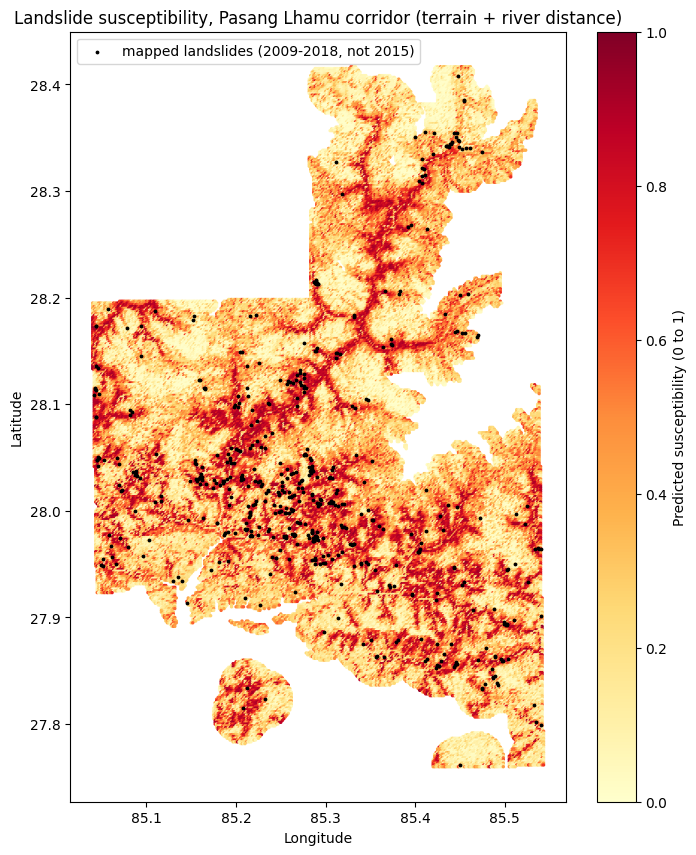

Saved susceptibility_map_river.png


In [13]:
## 10. Susceptibility map with river distance

feats_r = ["elevation", "slope", "curvature", "dist_river"]

model_r = RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                 random_state=42, n_jobs=-1)
model_r.fit(data_r[feats_r], data_r["landslide"])
print("Feature importance:")
print(pd.Series(model_r.feature_importances_, index=feats_r).round(3))

# same grid as the terrain-only map, plus distance to the nearest river
grid_r = grid[["elevation", "slope", "curvature"]].copy()
grid_r["dist_river"] = dist_to(river_tree, lon, lat)
grid_r = grid_r.dropna()
grid_r["risk"] = model_r.predict_proba(grid_r[feats_r])[:, 1]
lon_r, lat_r = lon[grid.index.isin(grid_r.index)], lat[grid.index.isin(grid_r.index)]

fig, ax = plt.subplots(figsize=(8, 10))
sc = ax.scatter(lon_r, lat_r, c=grid_r["risk"], s=2, cmap="YlOrRd", vmin=0, vmax=1)
ax.scatter(pl["lon"], pl["lat"], s=3, c="black", label="mapped landslides (2009-2018, not 2015)")
plt.colorbar(sc, label="Predicted susceptibility (0 to 1)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(loc="upper left")
ax.set_title("Landslide susceptibility, Pasang Lhamu corridor (terrain + river distance)")
plt.savefig("susceptibility_map_river.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved susceptibility_map_river.png")

**Result:** The second map (terrain + river distance, mean spatial-CV AUC 0.797) shows high susceptibility more sharply along river channels and valley floors than the terrain-only map (AUC 0.745). Distance to the nearest river became the most important feature (0.328), just ahead of slope (0.314), followed by elevation (0.201) and curvature (0.156).

Two maps are now available: terrain only (section 8, `susceptibility_map.png`) and terrain + river distance (this section, `susceptibility_map_river.png`). River distance may partly reflect valley position or mapping coverage, and OpenStreetMap rivers are incomplete, so the higher susceptibility near rivers is an association and not proof of cause.

## Summary of results

| Model | Mean AUC (spatial CV) |
|---|---|
| Terrain only (Map 1) | 0.745 |
| + rainfall | 0.767 |
| + river distance (Map 2) | 0.797 |
| + road distance | 0.744 |
| + rainfall + river + road | 0.807 |

## Limitations

- Landslide points end in 2018, so the map does not include recent events.
- Two maps were made: terrain only, and terrain + river distance. Rainfall (long-term mean, 5 km) and road distance were tested but not used in a map. Land cover and geology were not tested.
- 'No landslide' points are random points, not confirmed stable ground.


## Next steps

Land cover, geology, rainfall in the year of each landslide, and validation on recent road failures.
## Data credits

- Amatya, P. & Kirschbaum, D. (2021). High Mountain Asia Multitemporal Landslide Inventories, Version 1. NASA NSIDC DAAC.
- Copernicus DEM GLO-30, European Space Agency / Copernicus.
- Funk, C. et al. (2015). The Climate Hazards Infrared Precipitation with Stations (CHIRPS) dataset. Scientific Data.
- River and road data © OpenStreetMap contributors (ODbL).